# Lab Research Agent: from your question to a cited briefing

The agent of lab 01 (01_Build_an_Agent_From_Scratch) chose its tools turn by turn. Here the model **decides what to search for, which papers to read, and whether it has learned enough**, inside a loop whose order and round budget the code fixes. That is the pattern behind every "deep research" product, and you will build it in six small functions over **arXiv itself**: more than two million papers, searched live through its API, any topic, any field, up to yesterday.

```
your question ─▶ 1 plan searches (model) ─▶ 2 find candidate papers (arXiv API) ─▶ 3 select the ones worth reading (model)
              ─▶ 4 download each one, read it, summarize how it works (model) ─▶ 5 assess coverage: enough? (model) ──no──▶ back to 2
                                                                                                           └──yes, or budget used up──▶ 6 write the briefing, verify citations
```

Finding is cheap: a search returns titles and abstracts in a second. Reading is expensive: a PDF must be downloaded and extracted. So the agent finds widely, reads narrowly, and only ever reads what it chose.

This notebook is adapted from the lab *Research Agent* of the YASREF AI Agents course.

### Learning objectives

- **Build** the six steps of a research agent and read what the model decided at each one.
- **Trace** a weak decision -- a paper picked for a reason it does not support -- from step 3 into the summary and the briefing.
- **Check** the output with code (real ids only, numbered citations, references written by code) and know what such checks cannot see.
- **Write** the prompts that steer it: a specific topic, an honest summary, a definition of "enough", a critic.
- *Extras, if you finish early:* the same agent as a LangGraph graph, more topics, optional code challenges.

Every exercise is a **prompt** (or a topic): replace the text that says *Write your prompt here*, run the cell, and compare
with the output above it. arXiv changes every day, so your papers will differ from ours; the notes say "in our test run"
when they describe the run we made in October 2026.

### Setup: Runtime → Change runtime type → **T4 GPU**, then run this cell

In [1]:
!pip install -q -U transformers accelerate chromadb sentence-transformers pypdf arxiv

import torch, json, re

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


In [2]:
#@title Load Qwen3.5-4B (the same model in every lab)
import torch
from transformers import AutoTokenizer, AutoModelForImageTextToText

MODEL_ID = "Qwen/Qwen3.5-4B"                     # about 9 GB in float16: fits a free Colab T4
tok = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForImageTextToText.from_pretrained(
    MODEL_ID, dtype=torch.float16 if torch.cuda.is_available() else torch.float32, device_map="auto")
model.eval()
print("running on:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

config.json:   0%|          | 0.00/3.16k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 12.8MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/76.2k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

running on: Tesla T4


In [3]:
#@title chat(): the one function that talks to the model (the same in every lab)
def chat(messages, system=None, max_new_tokens=400, temperature=0.0, thinking=False, tools=None):
    """A prompt string or a list of {"role", "content"} messages -> the model's reply as text.
    system: an optional system prompt, put in front of the messages.
    temperature=0 is greedy (the same reply every time); above 0 it samples, with top_p=0.8 and top_k=20
    from the Qwen3.5 model card. thinking=True lets the model reason in <think>...</think> before answering.
    tools: tool schemas for native tool calling (the reply then may contain <tool_call> blocks)."""
    if isinstance(messages, str):
        messages = [{"role": "user", "content": messages}]
    if system:
        messages = [{"role": "system", "content": system}] + messages
    prompt = tok.apply_chat_template(messages, tools=tools, tokenize=False, add_generation_prompt=True,
                                     enable_thinking=thinking)                 # wrap in the model's own chat markup
    inputs = tok(prompt, return_tensors="pt").to(model.device)
    sampling = dict(do_sample=True, temperature=temperature, top_p=0.8, top_k=20) if temperature > 0 else dict(do_sample=False)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, pad_token_id=tok.pad_token_id, **sampling)
    return tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()  # keep only the new text

In [4]:
print(chat("Say hello in five words."))

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


Hello there, friend. How are you?


## 1: The source: arXiv, live

The `arxiv` package wraps arXiv's public API and respects its rate limit (one request every three seconds). A search returns metadata and the abstract for each paper; the PDF is only fetched later, for papers the agent selects. Everything the agent has seen in this session is kept in one dictionary, `PAPERS`, keyed by arXiv id.

In [5]:
import arxiv, requests, io, re, pandas as pd
from pypdf import PdfReader
from IPython.display import Markdown, display

api = arxiv.Client()                                                                   # polite by default: 3 s between requests, retries
PAPERS = {}                                                                            # id -> {title, year, authors, abstract, url, pdf, text}

def step(n, title, *lines):
    '''One banner per pipeline step, so every run reads the same way.'''
    print(f"\n{'━' * 72}\n Step {n} · {title}\n{'━' * 72}")
    for line in lines:
        print(line)

def search_arxiv(query, k=5):
    '''Ask arXiv for the k papers most relevant to a query. Returns their ids; metadata + abstract go into PAPERS.'''
    ids = []
    for r in api.results(arxiv.Search(query=query, max_results=k, sort_by=arxiv.SortCriterion.Relevance)):
        pid = r.get_short_id().split("v")[0]
        PAPERS.setdefault(pid, {"id": pid, "title": r.title.replace("\n", " "), "year": r.published.year, "authors": ", ".join(a.name for a in r.authors),
                                "abstract": r.summary.replace("\n", " "), "url": f"https://arxiv.org/abs/{pid}", "pdf": r.pdf_url, "text": None})
        ids.append(pid)
    return ids

In [6]:
search = search_arxiv                                                                  # the pipeline's source; swapped later for your own documents

for pid in search("mixture of experts inference cost", k=5):
    print(f"  {pid}  {PAPERS[pid]['year']}  {PAPERS[pid]['title'][:80]}")

  2410.17954  2024  ExpertFlow: Efficient Mixture-of-Experts Inference via Predictive Expert Caching
  2402.14800  2024  Not All Experts are Equal: Efficient Expert Pruning and Skipping for Mixture-of-
  2312.04693  2023  GraphMETRO: Mitigating Complex Graph Distribution Shifts via Mixture of Aligned 
  1806.08200  2018  Mixtures of Experts Models
  2503.03213  2025  Convergence Rates for Softmax Gating Mixture of Experts


In [7]:
first = PAPERS[next(iter(PAPERS))]                                                     # one entry; long fields shortened
for key, value in first.items():
    print(f"{key:>8}: {str(value)[:150]}{' ...' if len(str(value)) > 150 else ''}")
print(f"\n{len(PAPERS)} papers in PAPERS so far. 'text' stays None until the agent decides to read a paper.")

      id: 2410.17954
   title: ExpertFlow: Efficient Mixture-of-Experts Inference via Predictive Expert Caching and Token Scheduling
    year: 2024
 authors: Xin He, Shunkang Zhang, Kaijie Tang, Shaohuai Shi, Yuxin Wang, Zihao Zeng, Zhenheng Tang, Xiaowen Chu, Haiyan Yin, Ivor W. Tsang, Yew Soon Ong
abstract: Sparse Mixture-of-Experts (MoE) models can outperform dense large language models at similar computation by activating only a small set of experts per ...
     url: https://arxiv.org/abs/2410.17954
     pdf: https://arxiv.org/pdf/2410.17954v2
    text: None

5 papers in PAPERS so far. 'text' stays None until the agent decides to read a paper.





## 2: Reading a paper: download, extract, index

`fetch_text()` downloads the PDF once and extracts its text with `pypdf`; `read_index()` chunks that text and embeds it into a **reading index** for just the selected papers; `passages()` pulls the few chunks of one paper closest to the topic. Extraction from PDFs is imperfect (two columns, equations, footers) — this is real-world text now, not a curated dataset.

In [8]:
import chromadb
from chromadb.utils.embedding_functions import SentenceTransformerEmbeddingFunction

embedder = SentenceTransformerEmbeddingFunction(model_name="all-MiniLM-L6-v2", device="cuda")
client = chromadb.Client()

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (3 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [9]:
def fetch_text(pid):
    '''Download the PDF (once) and extract its text.'''
    paper = PAPERS[pid]
    if paper["text"] is None:
        pdf = requests.get(paper["pdf"], timeout=90).content
        text = "\n".join(page.extract_text() or "" for page in PdfReader(io.BytesIO(pdf)).pages)
        paper["text"] = re.sub(r"[ \t]+", " ", re.sub(r"-\n(?=[a-z])", "", text))     # re-join hyphenated words, collapse spaces
    return paper["text"]

def chunk(text, size=800):
    pieces, current = [], ""
    for word in text.split():
        if len(current) + len(word) > size:
            pieces.append(current.strip()); current = ""
        current += word + " "
    return pieces + [current.strip()]

def fresh_collection(name):
    '''A new, empty collection with that name (replacing any previous one).'''
    try:
        client.delete_collection(name)
    except Exception:
        pass
    return client.create_collection(name, embedding_function=embedder, metadata={"hnsw:space": "cosine"})

def read_index(ids):
    '''The reading index: chunk and embed the full text of just these papers.'''
    reading = fresh_collection("reading")
    for pid in ids:
        pieces = chunk(fetch_text(pid))
        reading.add(ids=[f"{pid}-{i}" for i in range(len(pieces))], documents=pieces, metadatas=[{"id": pid, "title": PAPERS[pid]["title"]}] * len(pieces))
    return reading

def passages(reading, topic, pid, k=6):
    '''The k passages of one paper most relevant to the topic.'''
    return reading.query(query_texts=[topic], n_results=k, where={"id": pid})["documents"][0]

In [10]:
pid = search("mixture of experts inference cost", k=1)[0]
reading = read_index([pid])
print(f"{PAPERS[pid]['title'][:70]}: {len(PAPERS[pid]['text']):,} characters, {reading.count()} chunks\n")
for i, passage in enumerate(passages(reading, "how are experts selected at inference time", pid, k=3), 1):
    print(f"passage {i}: {passage[:400]} ...\n")

ExpertFlow: Efficient Mixture-of-Experts Inference via Predictive Expe: 44,263 characters, 56 chunks

passage 1: ExpertFlow: Efficient Mixture-of-Experts Inference via Predictive Expert Caching and Token Scheduling Xin He1* , Shunkang Zhang2, Kaijie Tang3, Shaohuai Shi3, Yuxin Wang4, Zihao Zeng5, Zhenheng Tang2, Xiaowen Chu6, Haiyan Yin1, Ivor W. Tsang1,5, Yew Soon Ong1,5∗ 1CFAR, Agency for Science, Technology and Research (A*STAR), Singapore 2The Hong Kong University of Science and Technology, Hong Kong 3Ha ...

passage 2: doi:10.1109/ TON.2025.3649068 [34] Fuzhao Xue, Zian Zheng, Yao Fu, Jinjie Ni, Zangwei Zheng, Wangchunshu Zhou, and Yang You. 2024. OpenMoE: An Early Effort on Open Mixture-of-Experts Language Models. arXiv:2402.01739 [cs.CL] https://arxiv.org/abs/2402.01739 [35] Dianhai Yu, Liang Shen, Hongxiang Hao, Weibao Gong, Huachao Wu, Jiang Bian, Lirong Dai, and Haoyi Xiong. 2024. MoESys: A Distributed and  ...

passage 3: Changho Hwang, Xiaohu Tang, Ting Cao, and Mao Yang. 2

In our test run none of the three best passages explains how experts are selected: the paper's **first chunk** (title,
authors, affiliations, the start of the abstract), an **entry from the reference list** (a long author list), and the
**citation and license block**. Two of them repeat the title, and `chunk()` cuts by length, not by section, so front
matter and references compete with the content. This is real PDF text, and the same search picks the six passages per
paper that the model reads in step 4. (Dropping the reference list is an optional challenge in the Extras.)

<details><summary><b>Fallback if arXiv is slow or down today</b> — set <code>USE_DATASET = True</code> and run</summary>

The <code>jamescalam/ai-arxiv2</code> dataset holds 2,673 AI papers (2016 to early 2024) with clean full text. This cell loads them into <code>PAPERS</code>, indexes their abstracts locally, and points <code>search</code> at that index. Everything after this cell works unchanged.
</details>

In [11]:
USE_DATASET = False                                                                    # <- True only if arXiv is unavailable

def build_library(ids):
    '''A local search index over title + abstract of these papers (used instead of the arXiv API).'''
    library = fresh_collection("library")
    for i in range(0, len(ids), 500):
        batch = ids[i:i + 500]
        library.add(ids=batch, documents=[PAPERS[p]["title"] + ". " + PAPERS[p]["abstract"] for p in batch], metadatas=[{"title": PAPERS[p]["title"]} for p in batch])
    print(library.count(), "documents in the local library index")
    return library

def search_library(query, k=8):
    return library.query(query_texts=[query], n_results=min(k, library.count()))["ids"][0]

if USE_DATASET:
    from datasets import load_dataset
    for r in load_dataset("jamescalam/ai-arxiv2", split="train"):
        text = r["content"].encode("latin-1", "ignore").decode("utf-8", "ignore")
        PAPERS[r["id"]] = {"id": r["id"], "title": r["title"], "year": int(r["published"][:4]), "authors": r["authors"], "abstract": r["summary"].replace("\n", " "),
                           "url": f"https://arxiv.org/abs/{r['id']}", "pdf": None, "text": text[text.find("\n# "):] if "\n# " in text[:3000] else text}
    library = build_library(list(PAPERS))
    search = search_library

## 3: What do you want to know?

A question or a topic, in any field arXiv covers (physics, biology, economics, computer science...). The example is
deliberately broad: keep it for your first run, so that you can compare your output with the notes. Exercise 1 makes it specific.

In [12]:
TOPIC = "Small Language models against large language models"

## Step 1: Plan the searches — the model's first decision

A topic is not a search query. The model breaks it into three or four different searches that together cover it. This is where the agent decides *what to look for*.

In [13]:
#@title chat_json(): chat() that returns a dict
import json

def chat_json(messages, **kw):
    """chat(), but returns the first JSON object in the reply as a dict ({} if there is none).
    Small models sometimes write broken JSON: on a parse error, show the model the error and ask once more."""
    if isinstance(messages, str):
        messages = [{"role": "user", "content": messages}]
    for attempt in range(2):
        text = chat(messages, **kw)
        start = text.find("{")
        if start < 0:
            return {}
        try:
            return json.JSONDecoder().raw_decode(text[start:])[0]             # parse one object, ignore what follows
        except json.JSONDecodeError as err:
            messages = messages + [{"role": "assistant", "content": text},
                                   {"role": "user", "content": f"That JSON is invalid ({err}). Reply with only the corrected JSON."}]
    return {}

In [14]:
def plan(topic):
    reply = chat_json(f"You research a topic in the arXiv paper archive, which matches keywords, not sentences. Write 3-4 different "
                      f"keyword searches of 2-5 technical terms each (no question words, no 'large language models' on its own) that "
                      f'together cover the topic. Return JSON: {{"queries": [...]}} where every query is a plain string.\n\nTopic: {topic}')
    return [" ".join(map(str, q.values())) if isinstance(q, dict) else str(q) for q in reply.get("queries", [topic])]   # small models sometimes return objects

queries = plan(TOPIC)
step(1, "Plan searches (model)", *queries)


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 1 · Plan searches (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
small language models efficiency large language models performance
parameter efficient fine-tuning small models versus large models
distillation techniques small language models large language models
quantization methods small language models large language models inference


## Step 2: Find candidate papers

Each query goes to the source and the hits are pooled. arXiv matches keywords, so its own ranking is weak for a topic; we **re-rank the pool by meaning**, embedding each title + abstract and scoring its similarity to the topic (embedding search, as in the RAG labs). The ten best go forward. Cheap, fast, and deliberately generous: better to show the model ten candidates than to miss the right one.

In [15]:
def rank_by_meaning(topic, ids, keep=10):
    '''Embed each candidate's title + abstract and rank them by similarity to the topic -> {paper id: similarity}, best first.'''
    pool = fresh_collection("candidates")
    pool.add(ids=ids, documents=[PAPERS[p]["title"] + ". " + PAPERS[p]["abstract"] for p in ids])
    r = pool.query(query_texts=[topic], n_results=min(keep, len(ids)))
    return {pid: round(1 - d, 2) for pid, d in zip(r["ids"][0], r["distances"][0])}

def find_candidates(topic, queries, k=6, exclude=()):
    '''Pool the papers found by every query (de-duplicated), then re-rank the pool by meaning.'''
    pool = list(dict.fromkeys(pid for q in queries for pid in search(q, k) if pid not in exclude))
    return rank_by_meaning(topic, pool) if pool else {}

candidates = find_candidates(TOPIC, queries)
step(2, "Find candidates (re-ranked by meaning)", *[f"{score:.2f}  {pid}  {PAPERS[pid]['year']}  {PAPERS[pid]['title'][:75]}" for pid, score in candidates.items()])


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 2 · Find candidates (re-ranked by meaning)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
0.61  2405.11357  2024  Large Language Models Lack Understanding of Character Composition of Words
0.58  2610.00223  2026  A Holistic Assessment of the Carbon Footprint of Noor, a Very Large Arabic 
0.58  2403.17811  2024  Are Compressed Language Models Less Subgroup Robust?
0.56  2601.08844  2025  Emissions and Performance Trade-off Between Small and Large Language Models
0.56  2603.21389  2026  Task-Specific Efficiency Analysis: When Small Language Models Outperform La
0.51  2402.14800  2024  Not All Experts are Equal: Efficient Expert Pruning and Skipping for Mixtur
0.51  2501.05032  2025  Enhancing Human-Like Responses in Large Language Models
0.47  2602.08239  2026  Linearization Explains Fine-Tuning in Large Language Models
0.45  2110.06500  2021  Differentially Private Fine-tuning of La

## Step 3: Select the papers worth reading — the model's second decision

Similarity ranks by wording; the model ranks by usefulness. It reads the candidates' abstracts and picks the few that will actually answer the topic, with a one-sentence reason for each. Reading is the expensive step, so this choice matters.

In [16]:
def select_papers(topic, candidates, n=4):
    """The model picks the n most useful candidates -> [{"id", "why"}, ...]. Unknown ids are dropped."""
    listing = "\n".join(f"{pid}: {PAPERS[pid]['title']} ({PAPERS[pid]['year']}) — {PAPERS[pid]['abstract'][:300]}" for pid in candidates)
    reply = chat_json(f"Topic: {topic}\n\nCandidate papers:\n{listing}\n\nPick the {n} papers most useful for a briefing on the topic, "
                      f'most useful first, with one short sentence each on why. Return JSON: {{"papers": [{{"id": "...", "why": "one sentence"}}]}}',
                      max_new_tokens=400)
    chosen = [p for p in reply.get("papers", []) if p.get("id") in candidates][:n]
    return chosen or [{"id": pid, "why": "highest similarity to the topic"} for pid in list(candidates)[:n]]

chosen = select_papers(TOPIC, candidates)
step(3, "Select papers (model)", *[f"{PAPERS[c['id']]['title'][:80]}\n     why: {c['why']}" for c in chosen])


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 3 · Select papers (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Task-Specific Efficiency Analysis: When Small Language Models Outperform Large L
     why: This paper provides the first comprehensive task-specific efficiency analysis demonstrating scenarios where Small Language Models outperform Large Language Models, directly addressing the core comparison of capabilities versus cost.
Emissions and Performance Trade-off Between Small and Large Language Models
     why: It offers a critical investigation into the emissions and performance trade-off, quantifying the sustainability benefits of using fine-tuned Small Language Models as a viable alternative to resource-intensive Large Language Models.
Are Compressed Language Models Less Subgroup Robust?
     why: This study investigates the robustness of compressed (smaller) models against minority subgroups, providing essentia

### Something to highlight here: find the weakest pick

The model has to return four papers, so it picks four even when fewer fit, and it writes a reason for each. Read every
*why* next to the paper's title and abstract and ask: **does the paper itself study the topic, or does the reason build a
bridge the paper never makes?**

In our test run (October 2026) the weakest pick was *Large Language Models Lack Understanding of Character Composition
of Words*. It tests large models on character-level tasks and never compares small models with large ones; the reason
the model gave ("highlights specific cognitive limitations of LLMs that smaller models might avoid or handle
differently") is a guess the paper does not make. It ranked first in step 2 (similarity 0.61) because its title and
abstract share the topic's words. Follow your weakest pick through the next steps: it takes one of the four reading
slots, its summary in step 4 says it "directly addresses" the topic, and it gets a paragraph and a table row in the
briefing. (In an earlier test run its summary even claimed that small models "might offer more granular, character-aware
processing", and the briefing repeated it.) Your papers may differ; find your weakest pick the same way.

This happens because the topic never says which aspects we care about, so almost any paper about language models can be
argued into it.

> **Rule of thumb:** the vaguer your query → the more generic the answers you get.

**Exercise 1: A specific topic.** Rewrite the topic so that it says what you actually want to know: which comparison,
which aspects (accuracy? cost? energy? which tasks?). Replace *Write your topic here* and run: the cell repeats steps 1 to 3
for your topic and lists the papers both topics picked. `research()` runs on your topic later, so choose one you would
like a briefing on.

In [17]:
SPECIFIC_TOPIC = """When do small language models (a few billion parameters) match or beat large language models, on which tasks, and what do they save in compute, cost and energy?"""

if "Write your" in SPECIFIC_TOPIC:                                                     # not filled in yet: use the example topic
    print("Fill in SPECIFIC_TOPIC first -- using the example topic for now."); SPECIFIC_TOPIC = TOPIC
specific_queries = plan(SPECIFIC_TOPIC)
step(1, "Plan searches (model) · your specific topic", *specific_queries)
specific_candidates = find_candidates(SPECIFIC_TOPIC, specific_queries)
step(2, "Find candidates · your specific topic", *[f"{score:.2f}  {pid}  {PAPERS[pid]['year']}  {PAPERS[pid]['title'][:75]}" for pid, score in specific_candidates.items()])
specific_chosen = select_papers(SPECIFIC_TOPIC, specific_candidates)
step(3, "Select papers (model) · your specific topic", *[f"{PAPERS[c['id']]['title'][:80]}\n     why: {c['why']}" for c in specific_chosen])
print("\npicked for both topics:", [PAPERS[c["id"]]["title"][:70] for c in specific_chosen if c["id"] in {c0["id"] for c0 in chosen}] or "none")


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 1 · Plan searches (model) · your specific topic
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
small language models few billion parameters efficiency benchmarks
SLM vs LLM performance comparison specialized tasks
parameter efficient models inference cost energy consumption
small language model deployment latency and accuracy tradeoffs

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 2 · Find candidates · your specific topic
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
0.67  2603.21389  2026  Task-Specific Efficiency Analysis: When Small Language Models Outperform La
0.59  2508.15478  2025  SLM-Bench: A Comprehensive Benchmark of Small Language Models on Environmen
0.53  2505.08588  2025  Small but Significant: On the Promise of Small Language Models for Accessib
0.50  2608.05850  2026  MameLoshnLM: Yiddish Language Model a

**What to look for.** Compare the two step-3 lists. In our test run the specific topic raised the best similarity in
step 2 from 0.61 to 0.67 and brought in papers that measure small models directly (*SLM-Bench*, on performance and
environmental impact); only one paper, *Task-Specific Efficiency Analysis*, was picked for both topics. It did not make
every pick good: the fourth was a 2021 study of compute and energy trends in deep learning inference in general, picked
"to frame current SLM benefits". A specific topic narrows what the model can argue for; it does not replace reading the picks.

## Step 4: Read each paper and summarize how it works — the model's third decision

For every selected paper: download and extract the PDF, build the reading index, pull the six passages most relevant to the
topic, and write a structured summary from the abstract and those passages only. Problem, mechanism, results, relevance,
limitations. One summary per paper, so nothing gets blended together yet. The prompt is `SUMMARY_PROMPT`; the code fills in
`{topic}`, `{title}`, `{year}`, `{abstract}` and `{passages}`. Look at **Relevance to the topic** for your weakest pick.

In [18]:
SUMMARY_PROMPT = """You are summarizing one research paper for a briefing on: {topic}

Paper: {title} ({year})
Abstract: {abstract}

Relevant passages:
{passages}

Using only this material, write under these bold headings: **Problem**, **How it works** (3-4 sentences on the mechanism), **Key results** (numbers if given), **Relevance to the topic**, **Limitations**. Maximum 200 words."""

def summarize_paper(topic, pid, passages, prompt=SUMMARY_PROMPT):
    paper = PAPERS[pid]
    joined = "\n\n".join(f"- {p[:900]}" for p in passages)
    filled = (prompt.replace("{topic}", topic).replace("{title}", paper["title"]).replace("{year}", str(paper["year"]))
                    .replace("{abstract}", paper["abstract"][:1200]).replace("{passages}", joined))
    return chat(filled, max_new_tokens=380)

summaries = {}                                                                          # title -> summary text
reading = read_index([c["id"] for c in chosen])                                         # downloads the PDFs: ~5-10 s each
for c in chosen:
    title = PAPERS[c["id"]]["title"]
    summaries[title] = summarize_paper(TOPIC, c["id"], passages(reading, TOPIC, c["id"]))
    step(4, f"Read & summarize (model) : {title[:60]}"); display(Markdown(summaries[title]))


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) : Task-Specific Efficiency Analysis: When Small Language Model
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Large Language Models (LLMs) incur substantial computational costs, making them unsuitable for resource-constrained deployments despite their high performance.

**How it works**
The study introduces the Performance-Efficiency Ratio (PER), a novel metric integrating accuracy, throughput, memory, and latency via geometric mean normalization. It systematically evaluates 16 language models across five diverse NLP tasks to quantify efficiency.

**Key results**
Small models (0.5–3B parameters) achieved superior PER scores across all evaluated tasks, demonstrating that marginal accuracy gains from larger models do not justify the steep efficiency penalties.

**Relevance to the topic**
This paper provides the first comprehensive quantitative foundation establishing that Small Language Models (SLMs) outperform LLMs when prioritizing inference efficiency over marginal accuracy, validating their viability for practical, resource-limited applications.

**Limitations**
The provided text does not specify the exact computational resources or hardware constraints of the test environment, nor does it detail the specific NLP tasks used in the evaluation.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) : Emissions and Performance Trade-off Between Small and Large 
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Large Language Models (LLMs) face severe environmental concerns due to energy-intensive training and, more critically, repeated inference which can consume up to 90% of a model's total lifecycle energy.

**How it works**
The study compares fine-tuned Small Language Models (SLMs) against LLMs across Natural Language Processing, Reasoning, and Programming tasks. By focusing solely on inference emissions, the research evaluates whether smaller, specialized models can match the performance of massive models while drastically reducing carbon output.

**Key results**
In four out of six selected tasks, SLMs achieved comparable performance to LLMs. Specifically, in Natural Language Inference, fine-tuned SLMs reached 88.0–88.39% accuracy, outperforming the best LLM (DeepSeek-R1) at 80.0%. Inference emissions for these SLMs were approximately 1 milligram per query, significantly lower than LLMs.

**Relevance to the topic**
This paper directly addresses the viability of SLMs as sustainable alternatives to resource-heavy LLMs, demonstrating that smaller models can mitigate environmental impact without sacrificing accuracy in specific domains.

**Limitations**
The analysis is constrained to inference emissions only, excluding the energy costs of training. Furthermore, results are limited to six specific tasks across three categories, and the study relies on fine-tuned SLMs rather than evaluating raw small models.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) : Are Compressed Language Models Less Subgroup Robust?
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Large Language Models (LLMs) are expensive, prompting a shift to smaller compressed models. However, it is unclear if these compressed versions maintain robustness for minority subgroups within datasets, potentially exacerbating bias.

**How it works**
The study evaluates 18 distinct compression methods applied to BERT models across various datasets. It analyzes performance metrics, specifically worst-group accuracy (WGA), comparing results between different model sizes and compression techniques to determine if size alone dictates subgroup performance.

**Key results**
Worst-group performance depends on the compression method, not just model size. While average accuracy often drops as models shrink, WGA does not always worsen; in some cases, smaller models like TinyBERT outperform larger ones due to regularization effects. However, models with fewer than 6 layers fail completely (WGA = 0) on the SCOTUS dataset.

**Relevance to the topic**
This paper directly addresses the tension between efficiency and fairness. It demonstrates that model compression can improve subgroup robustness in specific contexts, challenging the assumption that smaller models are inherently less reliable for diverse populations.

**Limitations**
The analysis is restricted to BERT language models and specific compression techniques. Furthermore, the study identifies a minimum size threshold (6 layers) required to maintain subgroup performance, suggesting that extreme compression may be infeasible for certain tasks.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) : Large Language Models Lack Understanding of Character Compos
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Large Language Models (LLMs) excel at word, sentence, and document-level tasks but lack fundamental understanding of character composition. Despite character-level tasks being intuitively simpler, most LLMs fail to reliably perform even elementary tasks humans handle with perfection.

**How it works**
The study evaluates models like GPT-4, Mistral 7B, and Gemini 1.5 by sampling input texts from Wikipedia and randomly selecting target characters appearing at least once. The models are prompted to identify these specific characters within the text. Performance is measured using F-scores across multiple languages, including a dual-level assessment for Korean (characters vs. letters).

**Key results**
All tested models performed poorly across all languages and tasks. The F-scores were significantly lower than human performance, indicating a consistent failure to grasp basic character composition regardless of model size or language.

**Relevance to the topic**
This paper directly addresses the "Small Language models against large language models" theme by revealing a critical limitation shared by current LLMs. It suggests that scaling up parameters does not resolve the lack of atomic (character-level) understanding, implying that smaller models might not necessarily outperform larger ones on such fundamental tasks.

**Limitations**
The study relies on benchmarking against human performance on simple tasks, which may not fully capture the complexity of real-world applications. Additionally, the evaluation focuses primarily on English and Korean, limiting the generalizability of findings to other linguistic contexts.

**Exercise 2 · An honest "Relevance".** The prompt asks for a **Relevance to the topic** section, so the model writes one,
even for a paper that has nothing to say about the topic. Write an instruction for that heading that allows the answer
*not directly relevant*; the cell appends it to the end of `SUMMARY_PROMPT`. It then summarizes one paper again with the
new prompt and prints both relevance sections. It takes the model's own last pick (`chosen[-1]`, the least useful by its
own ranking); if you found a weaker one, put its id in `weakest`.

In [19]:
HONEST_PROMPT = SUMMARY_PROMPT + """
Under **Relevance to the topic**, first decide whether the paper itself studies the topic. If it does not, write exactly "Not directly relevant." and one sentence on what the paper studies, without mentioning the topic. Nowhere in the summary speculate about what the paper might imply for the topic."""

def relevance(summary):
    """The text under the **Relevance to the topic** heading (the whole summary if there is no such heading)."""
    m = re.search(r"\*\*Relevance to the topic\*\*:?\s*(.*?)(?=\n\s*\*\*|\Z)", summary, re.S)
    return m.group(1).strip() if m else summary

weakest = chosen[-1]["id"]                         # the model's own last pick; put the id of the pick you found weakest here
honest = summarize_paper(TOPIC, weakest, passages(reading, TOPIC, weakest), prompt=HONEST_PROMPT)
print(PAPERS[weakest]["title"])
print("\nSUMMARY_PROMPT -> Relevance to the topic:\n ", relevance(summaries[PAPERS[weakest]["title"]]))
print("\nyour prompt    -> Relevance to the topic:\n ", relevance(honest))

Large Language Models Lack Understanding of Character Composition of Words

SUMMARY_PROMPT -> Relevance to the topic:
  This paper directly addresses the "Small Language models against large language models" theme by revealing a critical limitation shared by current LLMs. It suggests that scaling up parameters does not resolve the lack of atomic (character-level) understanding, implying that smaller models might not necessarily outperform larger ones on such fundamental tasks.

your prompt    -> Relevance to the topic:
  Not directly relevant. This paper studies the fundamental limitation of LLMs in processing individual characters, contrasting their success with word-level tasks.


**What to look for.** In our test run `SUMMARY_PROMPT` said the character-composition paper "directly addresses the
limitations of Large Language Models"; with the instruction above, the model wrote "Not directly relevant." and one
sentence on what the paper studies. The exact wording mattered. While writing this lab we tried two other instructions
on the same paper: one that let the model write "Not directly relevant:" followed by a sentence still invented a link
to small models after the colon, and one that asked for "one sentence on what the paper itself shows about the topic"
produced the strongest invented claim of all. Check your version against the paper's abstract, not against what sounds right.

## Step 5: Assess coverage: enough, or search again? — the model's fourth decision

This is what a plain pipeline cannot do. The model reads its own summaries, names what the topic still lacks, and proposes
new searches for those gaps, or says it has enough. Forcing named gaps and concrete queries is meant to stop it from just
saying "yes, done". Watch what it does instead.

In [20]:
ASSESS_PROMPT = """Topic: {topic}

Paper summaries gathered so far:
{summaries}

Search queries already used: {queries}

Which aspects of the topic are still not covered by these papers? Propose at most 2 NEW keyword searches for the gaps (plain strings), or none if the summaries already cover the topic well.
Return JSON: {"gaps": [...], "new_queries": [...], "enough": true/false}"""

def assess(topic, summaries, used_queries, prompt=ASSESS_PROMPT):
    joined = "\n\n".join(f"### {title}\n{text[:700]}" for title, text in summaries.items())
    return chat_json(prompt.replace("{topic}", topic).replace("{summaries}", joined).replace("{queries}", str(used_queries)), max_new_tokens=300)

audit = assess(TOPIC, summaries, queries)
step(5, "Assess coverage (model)", f"gaps: {audit.get('gaps') or 'none'}", f"enough: {audit.get('enough')}", f"new queries: {audit.get('new_queries') or 'none'}")


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 5 · Assess coverage (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
gaps: ['The provided summaries cover efficiency, emissions, subgroup robustness, and character-level reasoning. However, they lack specific coverage on the architectural differences (e.g., MoE vs. Dense) and the specific challenges of deploying SLMs in real-time, low-latency edge devices (IoT) versus cloud environments.', "There is no mention of the 'hallucination' or 'reasoning' reliability of SLMs compared to LLMs in complex multi-step tasks, nor the specific techniques used to mitigate SLM hallucinations (e.g., retrieval-augmented generation specifically optimized for small models)."]
enough: False
new queries: ['small language models vs large language models edge device deployment latency', 'small language models hallucination mitigation reasoning capabilities']


**What to look for.** `enough: False`, with gaps such as, in our test run, mixture-of-experts architectures, serving
infrastructure and the interpretability of small models: things the topic never asked about. In every run we made of
this lab with this prompt (step by step, inside `research()`, in the LangGraph version, and on a T4) the model answered
`enough: False`. There is always another gap to name, and nothing in the prompt says what *enough* means. So in
practice the **round budget, not the model, ends the loop**.

**Exercise 3 · Define "enough".** Write an assess prompt that says when `enough` is true: what must the summaries cover,
and what does *not* count as a gap? Replace *Write your prompt here*; keep the placeholders and the JSON line. The cell
runs it on the same four summaries. Hint: the model writes the JSON fields in the order you ask for them.

In [21]:
ENOUGH_PROMPT = """Topic: {topic}

Paper summaries gathered so far:
{summaries}

Search queries already used: {queries}

Decide whether these papers are enough for a short briefing on the topic. "enough" is true when the summaries answer the topic's main question: at least two papers address it directly, with measured results. Aspects the topic does not ask about (other applications, other architectures, future trends) are not gaps. Only if "enough" is false, name the missing aspects of the topic and propose at most 2 NEW keyword searches for them (plain strings).
Return JSON: {"enough": true/false, "gaps": [...], "new_queries": [...]}"""

audit_defined = assess(TOPIC, summaries, queries, prompt=ENOUGH_PROMPT)
step(5, "Assess coverage (model) · your definition of enough", f"gaps: {audit_defined.get('gaps') or 'none'}",
     f"enough: {audit_defined.get('enough')}", f"new queries: {audit_defined.get('new_queries') or 'none'}")


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 5 · Assess coverage (model) · your definition of enough
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
gaps: none
enough: True
new queries: none


**What to look for.** In our test run the solution's definition (enough when at least two papers address the main
question with measured results; aspects the topic does not ask about are not gaps) gave `enough: True` and no gaps on
the same four summaries. While writing this lab we also ran that definition with the JSON fields in the original order,
`gaps` first, on the summaries of an earlier run: `enough: False` and two new gaps. The model writes the fields in
order, and once it has listed gaps it concludes it is not done. That is one run of each, so try both orders yourself.
`research()` below still uses `ASSESS_PROMPT`; putting your definition into the loop is an optional challenge in the Extras.

## Step 6: Write the briefing and verify the citations

The briefing is written from the summaries, not from raw chunks, so the prompt stays small and each paper is represented
fairly. The papers are numbered [1] to [n] in the prompt and the model cites them by number. Code then checks which of the
papers read the briefing cites, flags any number that is not a paper it read, counts the words, warns if the reply ran out
of tokens, and appends the reference list with real arXiv links.

Why numbers and not titles? Models shorten long titles and switch between brackets and italics; a check that looks for
exact titles in brackets then misses citations that are there, and finds "no unknown citations" because it found nothing to
check. A number in brackets is easy to ask for and easy to check with one regex. **It checks citations, not whether the
claims are true**: a sentence can cite [2] and still say something paper 2 never said (Exercise 4).

In [22]:
def cut_off(reply, max_new_tokens):
    """True if a reply used (almost) all of its token budget: it probably stops mid-sentence."""
    return len(tok(reply)["input_ids"]) >= max_new_tokens - 5

def write_briefing(topic, summaries, max_new_tokens=1200):
    """The papers are numbered [1]..[n] in the order of summaries; the briefing cites them by number."""
    joined = "\n\n".join(f"[{i}] {title}\n{text}" for i, (title, text) in enumerate(summaries.items(), 1))
    briefing = chat(f"Write a literature briefing on: {topic}\n\nUse ONLY the numbered paper summaries below. After every statement taken from a paper, "
                    f"cite the paper by its number in square brackets, like [2].\nStructure:\n1. **Overview** (2-3 sentences)\n"
                    f"2. **How the approaches work**: 2 sentences per paper\n3. **Comparison**: a markdown table with columns Paper | Approach | Trade-off\n"
                    f"4. **What is still open** (2-3 bullets)\nMaximum 350 words.\n\n{joined}", max_new_tokens=max_new_tokens)
    if cut_off(briefing, max_new_tokens):
        print(f"WARNING: the briefing used all {max_new_tokens} new tokens and is cut off. Raise max_new_tokens or ask for less.")
    return briefing

def verify(briefing, summaries, refs):
    """Which papers does the briefing cite as [n], and does it cite a number that was never read?
    It checks citations, not whether the claims are true."""
    titles = list(summaries)
    cited = {int(n) for group in re.findall(r"\[(\d+(?:\s*,\s*\d+)*)\]", briefing) for n in re.findall(r"\d+", group)}
    unknown = sorted(n for n in cited if not 1 <= n <= len(titles))
    never = [n for n in range(1, len(titles) + 1) if n not in cited]
    words = len(re.findall(r"[A-Za-z][A-Za-z'-]*", briefing))
    check = (f"about {words} words · cites {len(titles) - len(never)} of the {len(titles)} papers read" + (f" (never cites {never})" if never else "")
             + f" · {len(unknown)} citation{'s' if len(unknown) != 1 else ''} to papers that were not read{': ' + str(unknown) if unknown else ''}")
    references = "\n".join(f"{i}. {title} — {refs[title]}" for i, title in enumerate(titles, 1))
    return check, briefing + "\n\n**References**\n\n" + references

refs = {PAPERS[c["id"]]["title"]: PAPERS[c["id"]]["url"] for c in chosen}
briefing = write_briefing(TOPIC, summaries)
check, final = verify(briefing, summaries, refs)
step(6, "Briefing (model) + citation check", check); display(Markdown(final))


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 6 · Briefing (model) + citation check
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
about 368 words · cites 4 of the 4 papers read · 0 citations to papers that were not read


**Overview**
Recent literature highlights a paradigm shift where Small Language Models (SLMs) are increasingly validated as efficient, sustainable, and sometimes more robust alternatives to Large Language Models (LLMs). While SLMs offer superior performance-to-cost ratios and lower environmental footprints, they face specific challenges regarding extreme compression limits and fundamental character-level understanding.

**How the approaches work**
[1] Researchers introduce the Performance-Efficiency Ratio (PER) metric, which integrates accuracy, throughput, memory, and latency via geometric mean normalization to systematically evaluate model efficiency. This approach demonstrates that small models (0.5–3B parameters) achieve superior PER scores across diverse NLP tasks compared to larger counterparts.
[2] The study compares fine-tuned SLMs against LLMs by focusing exclusively on inference emissions to assess sustainability without sacrificing accuracy. It evaluates performance across Natural Language Processing, Reasoning, and Programming tasks to determine if smaller models can match massive ones while drastically reducing carbon output.
[3] The analysis evaluates 18 distinct compression methods applied to BERT models to determine if subgroup robustness depends on the compression technique rather than just model size. It measures worst-group accuracy (WGA) to challenge the assumption that smaller models are inherently less reliable for diverse populations.
[4] The study benchmarks models like GPT-4 and Mistral 7B on character-level tasks by randomly selecting target characters from Wikipedia texts to measure their ability to grasp atomic composition. Performance is assessed using F-scores across multiple languages to reveal fundamental limitations shared by models of varying sizes.

**Comparison**

| Paper | Approach | Trade-off |
| :--- | :--- | :--- |
| [1] | Performance-Efficiency Ratio (PER) | Marginal accuracy gains from larger models do not justify steep efficiency penalties. |
| [2] | Inference Emissions Analysis | SLMs achieve comparable performance with ~1mg query emissions vs. LLMs, reducing environmental impact. |
| [3] | Compression Method Evaluation | Subgroup robustness depends on compression technique; models with fewer than 6 layers fail completely on specific datasets. |
| [4] | Character-Level Benchmarking | Scaling up parameters does not resolve the lack of fundamental character composition understanding in LLMs. |

**What is still open**
*   The impact of training energy costs on the overall lifecycle emissions of SLMs remains unanalyzed in current inference-focused studies.
*   A clear minimum size threshold exists for subgroup performance, yet the optimal balance between extreme compression and robustness for diverse tasks is undefined.
*   The generalizability of character-level understanding findings is limited to specific languages like English and Korean, leaving broader linguistic contexts unexplored.

**References**

1. Task-Specific Efficiency Analysis: When Small Language Models Outperform Large Language Models — https://arxiv.org/abs/2603.21389
2. Emissions and Performance Trade-off Between Small and Large Language Models — https://arxiv.org/abs/2601.08844
3. Are Compressed Language Models Less Subgroup Robust? — https://arxiv.org/abs/2403.17811
4. Large Language Models Lack Understanding of Character Composition of Words — https://arxiv.org/abs/2405.11357

**What to look for.** Read the check line first. In our test run the briefing had about 340 words (we asked for at
most 350), cited all four papers by number, and finished well inside its 1,200-token budget. Small models treat a word
limit as a rough target: an earlier version of this prompt asked for "at most 450 words" with a 900-token budget, wrote
500 to 620 words, and with six papers was cut off mid-sentence. The WARNING line catches that case; the word count shows
how far the model went over. Then read the paragraph on your weakest pick: its citation is correct and the check passes,
and the paper still does not answer the topic.

## The whole agent

Steps 1 to 6 in one function, with the loop that makes it an agent: after step 5, if the model names gaps and new queries,
the agent goes back to step 2 for those gaps, reads more papers, and assesses again, until it says *enough* or the round
budget runs out. Budgets always beat the model's judgment. The line before the briefing says which of the two stopped it.

It runs on **your specific topic** from Exercise 1, with 3 papers in round 1 and 2 in round 2: about 6 minutes on a T4.

In [23]:
def research(topic, max_rounds=2, per_round=4):
    """Steps 1-6 with the loop. Returns (summaries, briefing)."""
    print(f"\nTOPIC: {topic}")
    queries, used, read_ids, summaries, refs = plan(topic), [], set(), {}, {}
    step(1, "Plan searches (model)", *queries)
    stop = f"round budget reached (max_rounds={max_rounds})"
    for round_no in range(1, max_rounds + 1):
        candidates = find_candidates(topic, queries, exclude=read_ids)                 # 2 · never re-read a paper
        used += queries;   step(2, f"Find candidates · round {round_no}", *[f"{score:.2f}  {PAPERS[pid]['year']}  {PAPERS[pid]['title'][:75]}" for pid, score in candidates.items()])
        if not candidates:
            stop = "no new papers found for these searches"; break
        chosen = select_papers(topic, candidates, n=per_round if round_no == 1 else 2)  # 3
        step(3, "Select papers (model)", *[f"{PAPERS[c['id']]['title'][:80]}\n     why: {c['why']}" for c in chosen])
        reading = read_index([c["id"] for c in chosen])                                # 4 · download + extract + index
        for c in chosen:
            title = PAPERS[c["id"]]["title"]
            summaries[title] = summarize_paper(topic, c["id"], passages(reading, topic, c["id"]))
            refs[title] = PAPERS[c["id"]]["url"]; read_ids.add(c["id"])
            step(4, f"Read & summarize (model) · {title[:60]}"); display(Markdown(summaries[title]))
        audit = assess(topic, summaries, used)                                         # 5
        step(5, "Assess coverage (model)", f"gaps: {audit.get('gaps') or 'none'}", f"enough: {audit.get('enough')}", f"new queries: {audit.get('new_queries') or 'none'}")
        if str(audit.get("enough")).lower() == "true":
            stop = "the model said enough"; break
        if not audit.get("new_queries"):
            stop = "the model proposed no new searches"; break
        queries = [str(q) for q in audit["new_queries"]]
    print(f"\nstopped: {stop}")
    if not summaries:
        step(6, "Briefing", "No papers found for these searches - rephrase the topic."); return summaries, ""
    briefing = write_briefing(topic, summaries)                                         # 6
    check, final = verify(briefing, summaries, refs)
    step(6, "Briefing (model) + citation check", f"{len(summaries)} papers read · {check}"); display(Markdown(final))
    return summaries, briefing

summaries, briefing = research(SPECIFIC_TOPIC, per_round=3)                             # your topic from Exercise 1: 3 papers, then 2 per round


TOPIC: When do small language models (a few billion parameters) match or beat large language models, on which tasks, and what do they save in compute, cost and energy?

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 1 · Plan searches (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
small language models few billion parameters efficiency benchmarks
SLM vs LLM performance comparison specialized tasks
parameter efficient models inference cost energy consumption
small language model deployment latency and accuracy tradeoffs

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 2 · Find candidates · round 1
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
0.67  2026  Task-Specific Efficiency Analysis: When Small Language Models Outperform La
0.59  2025  SLM-Bench: A Comprehensive Benchmark of Small Language Models on Environmen
0.53  2025  Small but Significant: On the Promise 

**Problem**
Large Language Models (LLMs) incur substantial computational costs, making them unsuitable for resource-constrained deployments like edge devices or real-time applications.

**How it works**
The study introduces the Performance-Efficiency Ratio (PER), a novel metric that integrates accuracy, throughput, memory, and latency via geometric mean normalization. It systematically evaluates 16 open-source models ranging from 0.5B to 72B parameters across five diverse NLP tasks to quantify the trade-off between performance and efficiency.

**Key results**
Small Language Models (0.5–3B parameters) achieved superior PER scores across all evaluated tasks. While some small models match the accuracy of larger counterparts, they offer significantly lower memory footprints and faster inference speeds.

**Relevance to the topic**
This paper directly addresses when small models beat large ones by providing quantitative proof that SLMs outperform LLMs in production environments prioritizing inference efficiency over marginal accuracy gains.

**Limitations**
The analysis focuses exclusively on open-source models and specific NLP tasks, potentially limiting generalizability to other domains or proprietary architectures.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) · SLM-Bench: A Comprehensive Benchmark of Small Language Model
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Despite the efficiency of Small Language Models (SLMs), systematic evaluations of their performance versus environmental impact remain lacking. Current benchmarks fail to holistically assess the trade-offs between accuracy, computational efficiency, and sustainability metrics required for real-world deployment.

**How it works**
SLM-Bench introduces a standardized, open-source pipeline evaluating 15 SLMs across 9 NLP tasks and 23 datasets. It tests models on four distinct hardware configurations to ensure fair comparisons. The framework quantifies 11 specific metrics spanning correctness, computation, and energy consumption to provide a comprehensive view of efficiency trade-offs.

**Key results**
The study highlights diverse trade-offs: some SLMs excel in accuracy while others achieve superior energy efficiency. Specific numerical performance figures or exact parameter counts for the 15 models are not provided in the text.

**Relevance to the topic**
This paper directly addresses when SLMs match or beat Large Language Models (LLMs) by rigorously measuring their environmental footprint and operational costs. It bridges the gap between resource efficiency and real-world applicability, offering data on compute savings and carbon reduction.

**Limitations**
The provided text does not specify the exact parameter counts of the 15 SLMs tested, nor does it detail the specific tasks where SLMs definitively outperform LLMs beyond general statements.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) · CSTutorBench: Benchmarking Small Language Models as Tutors f
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Deploying Large Language Models (LLMs) in K-12 settings raises privacy, cost, and reliance concerns. While Small Language Models (SLMs) offer a viable alternative, selecting the right model for specific domains like block-based programming—often absent from training data—remains difficult due to a lack of guidance.

**How it works**
CSTutorBench evaluates 11 models (4B–120B parameters) using 17 scenario-based questions within the VEX VR robotics environment. It employs an 8-criterion pedagogical rubric and an LLM-as-judge pipeline to score responses on surface-level criteria versus deeper behaviors like avoiding answer leakage and engaging with student debugging histories.

**Key results**
Models perform well on vocabulary and tone but struggle with deep pedagogical behaviors. Model family and instruction-tuning approach are better predictors of tutoring quality than parameter count alone.

**Relevance to the topic**
This research directly addresses when SLMs match LLMs in education. It suggests SLMs may suffice for surface tasks but fail on complex debugging guidance, offering critical insights into cost and energy savings only when specific model architectures are chosen correctly.

**Limitations**
The study is preliminary, relying on a specific block-based programming domain where training data is scarce. Furthermore, the evaluation depends on an LLM-as-judge pipeline, which introduces potential bias in scoring complex pedagogical interactions.

... (2 outputs left out)


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) · Position: LLM Inference Should Be Evaluated as Energy-to-Tok
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Current LLM inference evaluation focuses on accuracy, latency, and hardware utilization (MFU), ignoring physical constraints. This fails to answer the critical deployment question: how many quality-conditioned tokens can be produced given fixed limits on compute, delivered power, cooling, and PUE?

**How it works**
The paper formalizes inference as "energy-to-token production," where token rate is bounded by both compute-per-token and energy-per-token ceilings. System optimizations like KV-cache compression, sparse attention, quantization, and difficulty-adaptive reasoning are reframed as interventions that shift this energy-to-token frontier rather than just improving local benchmarks.

**Key results**
The text cites a 5–10× price gap between Chinese and US Pro tiers, and a 3–30× envelope when comparing cross-tier models. It notes global average PUE is 1.56, with industry leaders reaching 1.08–1.09.

**Relevance to the topic**
This directly addresses when small models match large ones by shifting the metric from theoretical peak compute to delivered power and operational efficiency. It suggests small models save compute, cost, and energy by moving the binding constraint from theoretical FLOPs to physical power limits, making them viable where large models exceed energy ceilings.

**Limitations**
The paper explicitly states that API price dispersion is used only as directional motivation, not causal evidence of marginal cost. Furthermore, it does not provide specific quantitative comparisons of small versus large model performance on specific tasks or exact energy savings figures.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 5 · Assess coverage (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
gaps: ['Long-context window efficiency: How do small models handle inputs with thousands or millions of tokens compared to large models?', 'Multimodal capabilities: Do small models match large models when processing images, audio, or video alongside text?', 'Fine-tuning and adaptation costs: What is the cost difference for customizing small models vs. large models for specific domains?', 'In-context learning (ICL) limits: At what point does the context window size become a bottleneck for small models compared to large ones?']
enough: False
new queries: ['small language models long context window efficiency thousands of tokens', 'small language models multimodal capabilities image audio video vs large models']

stopped: round budget reached (max_rounds=2)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

**Overview**
Small Language Models (SLMs) increasingly match or beat Large Language Models (LLMs) when production environments prioritize inference efficiency, energy constraints, or specific domain tasks over marginal accuracy gains. Research indicates that SLMs often achieve superior Performance-Efficiency Ratios and significantly lower operational costs, though their success depends heavily on the specific task complexity and architectural choices.

**How the approaches work**
The Performance-Efficiency Ratio (PER) metric integrates accuracy, throughput, memory, and latency via geometric mean normalization to quantify trade-offs across diverse NLP tasks [1]. SLM-Bench establishes a standardized pipeline evaluating 15 SLMs across nine tasks and four hardware configurations to holistically assess sustainability metrics like energy consumption [2]. CSTutorBench evaluates model performance in K-12 block-based programming using an 8-criterion pedagogical rubric to determine if parameter count alone predicts tutoring quality [3]. ARS employs adaptive certainty monitoring to dynamically suppress redundant reasoning steps in large models, achieving significant token and energy reductions without retraining [4]. Position reframes inference evaluation as "energy-to-token production," treating system optimizations as interventions that shift physical power limits rather than just improving local benchmarks [5].

**Comparison**

| Paper | Approach | Trade-off |
| :--- | :--- | :--- |
| [1] | Performance-Efficiency Ratio (PER) | SLMs (0.5–3B) beat LLMs in PER by offering lower memory footprints and faster speeds despite matching accuracy [1]. |
| [2] | SLM-Bench Pipeline | Trade-offs exist where some SLMs excel in accuracy while others achieve superior energy efficiency, but exact parameter counts are unspecified [2]. |
| [3] | Pedagogical Rubric | SLMs suffice for surface tasks like vocabulary but fail on complex debugging guidance, making cost savings conditional on architecture [3]. |
| [4] | Adaptive Reasoning Suppression | Optimizes large models for efficiency (57.9% energy savings) rather than comparing SLMs directly to LLMs [4]. |
| [5] | Energy-to-Token Production | SLMs save compute and energy by moving the binding constraint from theoretical FLOPs to physical power limits [5]. |

**What is still open**
*   Specific quantitative comparisons of SLM versus LLM performance on complex tasks remain limited, with many studies focusing on open-source models or narrow domains [1][2].
*   The exact parameter counts and specific numerical performance figures for the models tested in comprehensive benchmarks are often not provided in the literature [2].
*   Generalizability of SLM superiority across proprietary architectures and non-NLP domains requires further investigation beyond current open-source analyses [1].

**References**

1. Task-Specific Efficiency Analysis: When Small Language Models Outperform Large Language Models — https://arxiv.org/abs/2603.21389
2. SLM-Bench: A Comprehensive Benchmark of Small Language Models on Environmental Impacts--Extended Version — https://arxiv.org/abs/2508.15478
3. CSTutorBench: Benchmarking Small Language Models as Tutors for Block-Based Programming — https://arxiv.org/abs/2607.05571
4. ARS: Adaptive Reasoning Suppression for Efficient Large Reasoning Language Models — https://arxiv.org/abs/2510.00071
5. Position: LLM Inference Should Be Evaluated as Energy-to-Token Production — https://arxiv.org/abs/2605.11733

**What made it agentic.** The model chose the searches, chose the papers, judged its own coverage and proposed where to
search next; the code only fixed the order of steps, the budgets (`max_rounds`, `per_round`) and the checks (real ids
only, numbered citations, references from code). Compare with the SQL Data Analyst homework, where the model never
decided *whether* to take another step.

**Read round 2 critically.** In our test run the model said `enough: False` after both rounds, so the line before the
briefing reads `stopped: round budget reached`. Round 2's gap searches found mostly weak candidates: the best was a
carbon-footprint study of one very large Arabic model (0.64), six of the ten scored below 0.4, and three were about
mobile edge computing (0.11 to 0.19). `select_papers` must still pick two, and the model chose a 2021 study of inference
trends in deep learning (0.50) and a prompt-optimization method for large reasoning models (0.43); both summaries then
claim a link to small language models that the papers do not make. Searching again only helps when the new searches
find something. An agent that can say "arXiv has little on this gap" needs a similarity threshold (an optional
challenge in the Extras).

**Exercise 4 · A critic.** The citation check proves that every [n] points to a paper that was read; it cannot see
whether the sentence says what that paper said. Write a critic prompt: the model gets the topic, the abstracts of the
papers read (the source, not the step-4 summaries) and the briefing `research()` just wrote, and goes through the
briefing claim by claim. Keep `{topic}`, `{papers}` and `{briefing}`, and have it mark each claim SUPPORTED or NOT
SUPPORTED: the code counts the NOT SUPPORTED lines. The wrapper `critique()` is given.

In [24]:
CRITIC_PROMPT = """You check a literature briefing on the topic "{topic}" against the papers it cites, given below by number, title and abstract.

Papers:
{papers}

Briefing:
{briefing}

Go through the briefing claim by claim. For every sentence that cites a paper [n], write one line:
[n] | the claim in a few words | SUPPORTED or NOT SUPPORTED | why, in a few words
A claim is NOT SUPPORTED when the paper's abstract does not state it, in particular a conclusion about the topic that the paper itself never draws. Do not skip any cited sentence."""

def critique(topic, briefing, summaries, prompt=CRITIC_PROMPT, max_new_tokens=900):
    """A second model call: check the briefing against the abstracts of the papers it cites -- the source, not the step-4 summaries."""
    by_title = {paper["title"]: paper for paper in PAPERS.values()}
    papers = "\n\n".join(f"[{i}] {title}\nAbstract: {by_title[title]['abstract']}" for i, title in enumerate(summaries, 1))
    review = chat(prompt.replace("{topic}", topic).replace("{papers}", papers).replace("{briefing}", briefing), max_new_tokens=max_new_tokens)
    if cut_off(review, max_new_tokens):
        print(f"WARNING: the review used all {max_new_tokens} new tokens and is cut off.")
    return review

review = critique(SPECIFIC_TOPIC, briefing, summaries)
print(review)
print("\nlines marked NOT SUPPORTED (counted by code):", review.count("NOT SUPPORTED"))

[1] | SLMs beat LLMs in PER | SUPPORTED | Abstract confirms SLMs achieve superior PER scores.
[1] | SLMs offer lower memory and faster speeds | SUPPORTED | Abstract notes superior PER through geometric mean including memory and latency.
[1] | SLMs match accuracy despite efficiency gains | SUPPORTED | Abstract states SLMs achieve superior PER across all tasks.
[2] | SLM-Bench evaluates 15 models on 9 tasks | SUPPORTED | Abstract explicitly states evaluation of 15 SLMs on 9 NLP tasks.
[2] | SLM-Bench assesses sustainability metrics | SUPPORTED | Abstract mentions quantifying metrics including consumption and sustainability.
[2] | Some SLMs excel in accuracy while others in energy efficiency | SUPPORTED | Abstract highlights diverse trade-offs where some excel in accuracy and others in energy efficiency.
[2] | Exact parameter counts are unspecified | SUPPORTED | Abstract does not list specific parameter counts for the 15 models.
[3] | CSTutorBench uses an 8-criterion pedagogical rubric | 

**What to look for.** Count and read the NOT SUPPORTED lines. In our test run the critic checked 19 claims and marked
one NOT SUPPORTED, the "8-criterion pedagogical rubric" of [3]. That is a false alarm: the number is in the paper's text
(step 4 read it), not in its abstract. And it let through a sentence that stretches a paper toward the topic: the
overview cites [4], a 2021 study of inference trends in deep learning in general, for small models' lower energy use.
On a briefing from an earlier run, the same prompt did flag that run's invented link ("SLMs might offer more granular,
character-aware processing") as NOT SUPPORTED, while a first critic prompt that ended with *If every claim is supported,
answer: All claims supported* got exactly that answer, four tokens long. A critic is a second opinion with its own blind
spots: give it the evidence, make it go claim by claim, and let code do the counting (when we asked the model for a
count at the end of its list, the count was wrong).

## 🗂️ Your turn: your own papers or reports

Upload the documents you actually work with (`.pdf .txt .md`): papers, reports, proposals, standards. They go into `PAPERS` (the first 1,200 characters stand in for the abstract), a local index over them replaces arXiv as the source, and the same `research()` runs with the same banners. Nothing leaves this Colab session.

In [25]:
from google.colab import files
from pypdf import PdfReader

def upload():
    """Open the file picker; return {filename: text} for .pdf / .txt / .md / .csv files."""
    texts = {}
    for name, blob in files.upload().items():
        if name.lower().endswith(".pdf"):
            open(name, "wb").write(blob)
            texts[name] = "\n".join(page.extract_text() or "" for page in PdfReader(name).pages)
        else:
            texts[name] = blob.decode("utf-8", errors="ignore")
    print({k: f"{len(v)} chars" for k, v in texts.items()})
    return texts

In [26]:
mine = upload()
for name, text in mine.items():
    PAPERS[name] = {"id": name, "title": name, "year": 2026, "authors": "", "abstract": text[:1200].replace("\n", " "), "url": name, "pdf": None, "text": text}
library = build_library(list(mine))                                                    # a local index over YOUR documents ...
search = search_library                                                                # ... and it becomes the source. research() is unchanged.
summaries, briefing = research(input("What do you want to know about these documents? ").strip() or "What problem do these documents address, how do their approaches work, and how do they differ?")

Saving Artificial Intelligence 2026.pdf to Artificial Intelligence 2026.pdf
{'Artificial Intelligence 2026.pdf': '85400 chars'}
1 documents in the local library index
What do you want to know about these documents? what is it about?

TOPIC: what is it about?

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 1 · Plan searches (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
neural architecture search automated design
transformer attention mechanisms efficiency
reinforcement learning training optimization
pre-training scaling laws generalization

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 2 · Find candidates · round 1
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
0.09  2026  Artificial Intelligence 2026.pdf

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 3 · Select papers (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

**Problem**
The KAUST Academy 2026 program addresses a national need for local talent in critical technologies driving Saudi Arabia's Vision 2030, specifically in AI, bioinformatics, cybersecurity, energy transition, and water sustainability. It solves the gap where students from diverse academic backgrounds lack the specialized training required for real-world project work.

**How it works**
The program operates in three progressive stages: online Coursera courses, intensive in-person training at local universities, and a final summer residency at KAUST or international partners like CERN and Oxford. Students collaborate with mentors on specific projects, utilizing AI tools and scientific frameworks to solve complex challenges, such as creating conversational interfaces for astronomical data or automating compliance workflows.

**Key results**
289 talented students from 15 nationalities completed 138 distinct projects. The Artificial Intelligence specialization accounted for 155 of these projects, while Cybersecurity had 60. The cohort included 34% female students and utilized 33 different project mentors across 33 host institutions.

**Relevance to the topic**
This document serves as a comprehensive summary of the 2026 KAUST Academy Specializations, detailing the curriculum, student demographics, and specific outcomes of the Artificial Intelligence track. It highlights successful applications of AI in fields like astronomy and enterprise compliance.

**Limitations**
The provided text is a summary of a graduation booklet rather than a single empirical research paper; therefore, it lacks deep methodological analysis, statistical significance testing, or detailed error analysis for individual projects.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 5 · Assess coverage (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
gaps: ['Practical implementation of AI in Saudi Vision 2030 specific sectors (energy, water, bioinformatics)', 'Ethical AI governance and local talent development frameworks in the Middle East', 'Interdisciplinary collaboration models for AI and scientific research in emerging economies']
enough: False
new queries: ['AI Vision 2030 Saudi Arabia implementation energy water bioinformatics', 'ethical AI governance frameworks Middle East emerging economies']

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 2 · Find candidates · round 2
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

stopped: no new papers found for these searches

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 6 · Briefing (model) + citation check
━━━━━━━━━━

### Literature Briefing: KAUST Academy 2026 AI Specialization

**Overview**
The KAUST Academy 2026 program addresses a national talent gap in Saudi Arabia's Vision 2030 by training students in critical technologies like AI and cybersecurity. It bridges the divide between diverse academic backgrounds and real-world project requirements through a structured, multi-stage curriculum. [1]

**How the approaches work**
The program initiates with online Coursera courses followed by intensive in-person training at local universities. [1] Participants culminate their learning with a summer residency at KAUST or international partners like CERN, where they collaborate with mentors on specific technical challenges. [1]

**Comparison**

| Paper | Approach | Trade-off |
| :--- | :--- | :--- |
| [1] | Progressive stages: Online courses, in-person training, and international residencies. | Lacks deep methodological analysis and statistical significance testing due to being a summary of a graduation booklet. |

**What is still open**
*   The specific impact of the program on long-term career trajectories or retention rates of the 289 graduates remains unquantified. [1]
*   Detailed error analysis and performance metrics for individual student projects, particularly in the AI specialization, are not provided. [1]
*   The scalability of this specific three-stage model to other national contexts or different critical technology sectors requires further empirical study. [1]

**References**

1. Artificial Intelligence 2026.pdf — Artificial Intelligence 2026.pdf

#### If the briefing is thin, read the banners in order: were the step 1 searches good keyword queries for your topic? Did step 2 find papers with similarity above about 0.5 (arXiv matches keywords: rephrase the searches)? Did step 3 pick the ones you would have picked? Was the extracted text in step 4 readable? Each step has its own fix.

## Summary

| Step | Who decides | Function |
|---|---|---|
| 1 Plan searches | **model** | `plan()` |
| 2 Find candidates, re-rank by meaning | code · arXiv API (or your local index) + embeddings | `find_candidates()`, `rank_by_meaning()` |
| 3 Select papers | **model** | `select_papers()` |
| 4 Download, read and summarize | **model**, reading index | `fetch_text()`, `read_index()`, `passages()`, `summarize_paper()` |
| 5 Assess coverage, loop or stop | **model** proposes; `max_rounds` stops it | `assess()` |
| 6 Briefing and citation check | **model**, then code | `write_briefing()`, `verify()` |

- **Find widely, read narrowly.** Searching is cheap and reading is expensive, so the model chooses what to read and code
  keeps it to real ids.
- **A weak decision travels.** A paper picked for a reason it does not support gets a "relevance" in its summary and a
  paragraph in the briefing. A specific topic (Exercise 1) and a summary prompt that allows "not directly relevant"
  (Exercise 2) stop it early.
- **"Enough" means nothing until you define it.** With no definition, the model always found another gap and the round
  budget ended the loop (Exercise 3). Budgets are not optional.
- **Make output checkable, then check it with code.** Numbered citations and one regex replace fragile title matching.
  Such checks prove the format, not the truth; a critic against the sources (Exercise 4) is a second check with its own
  blind spots.
- **Read the banners.** Every step prints what it decided, so a weak briefing can be traced to the step that caused it.

*Papers come from [arXiv](https://arxiv.org) through its public API; each keeps its own license. Fallback dataset: [jamescalam/ai-arxiv2](https://huggingface.co/datasets/jamescalam/ai-arxiv2).*

---
# Extras (if you finish early)

The same agent written as a LangGraph graph, a loop for more topics, and optional code challenges. Nothing in the core
depends on these cells.

## The same agent as a graph — LangGraph

`research()` is a loop with a budget and one decision inside it. Written as a graph, the loop becomes a **cycle** with a
conditional edge, the budget becomes a routing rule, and the state after every step is something you can inspect,
checkpoint or resume. The six functions do not change; the graph only decides which one runs next. The first cell builds
the graph, the second draws it. Running it is optional (`RUN_GRAPH = True`): it repeats the whole agent with 4 + 2 papers, roughly
8 minutes on a T4.

In [27]:
!pip install -q "langgraph>=0.6"

from typing import TypedDict
from langgraph.graph import StateGraph, START, END

MAX_ROUNDS = 2                                                             # the same budget as research()'s defaults

class Research(TypedDict, total=False):                                    # everything research() kept in local variables
    topic: str
    queries: list
    used: list
    read_ids: list
    summaries: dict
    refs: dict
    round: int
    audit: dict
    briefing: str

def plan_node(s):
    queries = plan(s["topic"]); step(1, "Plan searches (model)", *queries)
    return {"queries": queries, "used": [], "read_ids": [], "summaries": {}, "refs": {}, "round": 0}

def read_node(s):                                                          # steps 2, 3 and 4: one round of finding and reading
    round_no = s["round"] + 1
    candidates = find_candidates(s["topic"], s["queries"], exclude=set(s["read_ids"]))
    step(2, f"Find candidates · round {round_no}", *[f"{score:.2f}  {PAPERS[pid]['year']}  {PAPERS[pid]['title'][:75]}" for pid, score in candidates.items()])
    summaries, refs, read_ids = dict(s["summaries"]), dict(s["refs"]), list(s["read_ids"])
    if candidates:
        chosen = select_papers(s["topic"], candidates, n=4 if round_no == 1 else 2)
        step(3, "Select papers (model)", *[f"{PAPERS[c['id']]['title'][:80]}\n     why: {c['why']}" for c in chosen])
        reading = read_index([c["id"] for c in chosen])
        for c in chosen:
            title = PAPERS[c["id"]]["title"]
            summaries[title] = summarize_paper(s["topic"], c["id"], passages(reading, s["topic"], c["id"]))
            refs[title] = PAPERS[c["id"]]["url"]; read_ids.append(c["id"])
            step(4, f"Read & summarize (model) · {title[:60]}"); display(Markdown(summaries[title]))
    return {"round": round_no, "summaries": summaries, "refs": refs, "read_ids": read_ids, "used": s["used"] + s["queries"]}

def assess_node(s):
    audit = assess(s["topic"], s["summaries"], s["used"]) if s["summaries"] else {"enough": True, "gaps": ["no papers found"]}
    step(5, "Assess coverage (model)", f"gaps: {audit.get('gaps') or 'none'}", f"enough: {audit.get('enough')}", f"new queries: {audit.get('new_queries') or 'none'}")
    return {"audit": audit, "queries": [str(q) for q in audit.get("new_queries") or []]}

def brief_node(s):
    briefing = write_briefing(s["topic"], s["summaries"])
    check, final = verify(briefing, s["summaries"], s["refs"])
    step(6, "Briefing (model) + citation check", f"{len(s['summaries'])} papers read · {check}"); display(Markdown(final))
    return {"briefing": briefing}

def enough(s):                                                             # the one decision the loop was made of
    if str(s["audit"].get("enough")).lower() == "true":
        reason = "the model said enough"
    elif not s["queries"]:
        reason = "the model proposed no new searches"
    elif s["round"] >= MAX_ROUNDS:
        reason = f"round budget reached (MAX_ROUNDS={MAX_ROUNDS})"
    else:
        return "read"
    print(f"\nstopped: {reason}")
    return "brief"

graph = StateGraph(Research)
for name, fn in [("plan", plan_node), ("read", read_node), ("assess", assess_node), ("brief", brief_node)]:
    graph.add_node(name, fn)
graph.add_edge(START, "plan")
graph.add_edge("plan", "read")
graph.add_edge("read", "assess")
graph.add_conditional_edges("assess", enough, {"read": "read", "brief": "brief"})
graph.add_edge("brief", END)
researcher = graph.compile()

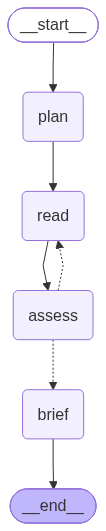

In [28]:
from IPython.display import Image
try:
    display(Image(researcher.get_graph().draw_mermaid_png()))               # the loop, drawn by the library from the edges
except Exception:
    print(researcher.get_graph().draw_mermaid())                            # the same diagram as text, if the renderer is unreachable

In [29]:
RUN_GRAPH = False                     # optional: True runs the whole agent again as a graph (about 10 minutes on a T4)
if RUN_GRAPH:
    result = researcher.invoke({"topic": SPECIFIC_TOPIC})                 # same functions, same banners; fetched PDFs are reused

Same six functions, same banners, the same budget as `research()`'s defaults (2 rounds; 4 papers, then 2). What changed is
that the loop is now a drawing, the state after every node can be saved and resumed, and a second person can read the
control flow without reading `research()`. When the shape of an agent is a cycle with a decision in it, this is the tool
built for that shape.

## Another topic

Back to arXiv: type a topic, read the banners, type the next one; an empty line or `quit` stops. Each topic takes roughly
8 minutes on a T4.

In [30]:
search = search_arxiv                                                                  # back to arXiv; another topic, 'quit' to stop
while True:
    q = input("Research topic: ").strip()
    if q.lower() in ("quit", "exit", "q", ""): break
    research(q)

Research topic: swimming

TOPIC: swimming

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 1 · Plan searches (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
swimming stroke biomechanics hydrodynamics
propulsive efficiency drag reduction aquatic propulsion
swimming performance training methodology
hydrofoil swimming underwater propulsion

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 2 · Find candidates · round 1
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
0.45  2017  Continuous Video to Simple Signals for Swimming Stroke Detection with Convo
0.44  2023  Validation of a propulsion model in front crawl swimming
0.42  2015  On the hydrodynamics of swimming enzymes
0.37  2026  Measurements and modeling of swimming speed dependence on stroke frequency 
0.35  2024  A Novel Aerial-Aquatic Locomotion Robot with Variable Stiffness Propulsion 
0.35  2013  The role of SE(d

**Problem**
Coaches require accurate stroke rate analysis for swimming training, but manually labeling every stroke in continuous race video is laborious and error-prone. Existing methods often rely on constrained lab settings or complex, non-end-to-end pipelines, failing to generalize to natural broadcast footage.

**How it works**
The system employs a Convolutional Neural Network (CNN) to map a sliding window of video frames directly to a smooth 1D target signal. Peaks in this generated signal correspond to discrete swimming strokes. The model utilizes early fusion of input features and 3D architectures to capture motion dynamics, trained with sine-transformed labels and label smoothing for numerical accuracy.

**Key results**
The method achieved 0% error in stroke rate prediction, significantly outperforming prior approaches which averaged 5% error. The 3D CNN model missed very few strokes, demonstrating high precision. The approach successfully generalized to tennis strokes without architectural modification.

**Relevance to the topic**
This research provides an automated, end-to-end solution for extracting discrete event metrics from continuous sports video. It enables real-time or post-race analysis of stroke rates using natural video, removing the need for manual annotation and reducing reliance on controlled laboratory environments.

**Limitations**
Performance may degrade on rare stroke types, such as dive shots lacking a back-swing, which require more specific training data. Additionally, the dataset contains limited occlusions caused by foreground objects, and the method assumes preprocessed, single-swimmer lanes extracted from color information.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) · Validation of a propulsion model in front crawl swimming
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
The study aims to validate a propulsion model proposed by Carmigniani et al. (2020) that explains coordination changes in front crawl swimming, specifically regarding how swimmers transition between different propulsion regimes.

**How it works**
The model outlines two distinct regimes based on velocity. In the low-speed gliding regime, swimmers increase thrust to boost velocity while maintaining constant coordination. At a critical velocity, swimmers reach maximum force; to continue accelerating, they must increase the relative propulsion time rather than generating more force.

**Key results**
A 5x25 m progressive speed test with instrumented paddles confirmed the model's algebraic solution and data agreement. Two swimmers exhibited different behaviors: one remained in the maximum force regime throughout, while the other clearly transitioned from a gliding regime (first 25 m) to a maximum force regime (last two lengths).

**Relevance to the topic**
Front crawl is the most efficient stroke for reaching highest speeds in competitive swimming. Validating this model provides critical insights into the biomechanics of propulsion, helping optimize technique for speed and energy efficiency across varying distances.

**Limitations**
The study notes that future work is required to test more swimmers to further comfort these results. Additionally, one participant's speed range was too narrow to fully observe the gliding regime, limiting the generalizability of the findings.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) · Measurements and modeling of swimming speed dependence on st
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Existing analytical models for jellyfish swimming rely on hydrozoan jet propulsion data, ignoring the paddling mechanics of scyphozoan species. Furthermore, the relationship between stroke frequency and swimming speed in these paddling swimmers has not been previously explored.

**How it works**
Scyphozoan jellyfish propel themselves by passing a wave of lateral displacement from anterior to posterior. This motion generates vortices on either side of the animal, transferring rearward momentum to the fluid to drive forward motion. Efficiency is enhanced by passive energy recapture via interactions between wake vortices and the subumbrellar surface.

**Key results**
Stroke frequency significantly impacts speed in a non-monotonic manner, with peak speeds occurring at 0.55 Hz. Aurelia aurita and Cassiopea xamachana displayed similar speed-frequency relationships despite differing natural frequencies. The paddling vortex model accurately predicted an 83% speed increase, whereas momentum and jetting models failed.

**Relevance to the topic**
Scyphozoan jellyfish exhibit the highest locomotive efficiency in the animal kingdom, making them ideal for bioinspired robotics and fluid dynamics research. Understanding their unique paddling mechanics provides critical insights for optimizing undulatory propulsion systems.

**Limitations**
The study utilized a biohybrid technique to control muscle contraction in live jellyfish, which may alter natural swimming behaviors. Additionally, the abstract cuts off before detailing the specific peak speed value or the full range of tested frequencies.

... (5 outputs left out)

**Problem**
Traditional visual illusions rely on static spatial manipulations. This paper addresses the challenge of creating "Progressive Semantic Illusions," where a single sketch undergoes a dramatic semantic transformation (e.g., duck to sheep) through sequential stroke addition, requiring the initial strokes to serve as a coherent foundation for two distinct concepts simultaneously.

**How it works**
The Stroke of Surprise framework uses a sequence-aware joint optimization with a dual-branch Score Distillation Sampling (SDS) mechanism. Unlike sequential methods that freeze the initial state, it dynamically adjusts prefix strokes to discover a "common structural subspace" valid for both targets. A novel Overlay Loss enforces spatial complementarity, ensuring structural integration rather than occlusion during the sequential addition of delta strokes.

**Key results**
Joint optimization achieved a concealment CLIP score of 2.421, significantly outperforming sequential optimization (1.520). Simple concept transformations (e.g., rabbit to horse) succeed with 8–16 strokes, while complex subjects like Einstein require 32–64 strokes.

**Relevance to the topic**
This research expands visual anagrams from the spatial to the temporal dimension, offering new generative techniques for creating dynamic, multi-stage visual illusions using vector sketches.

**Limitations**
The method requires careful tuning of the stroke budget; insufficient strokes compromise recognizability, while excessive strokes increase computational cost. Additionally, minor variations in stroke geometry arise from CUDA nondeterminism.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 5 · Assess coverage (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
gaps: ['Injury prevention and rehabilitation protocols for swimmers', 'Psychological aspects of competitive swimming (e.g., mental toughness, anxiety management)']
enough: False
new queries: ['swimming injury prevention rehabilitation protocols shoulder strain', 'psychological mental toughness competitive swimming performance']

stopped: round budget reached (max_rounds=2)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 6 · Briefing (model) + citation check
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
6 papers read · about 318 words · cites 6 of the 6 papers read · 0 citations to papers that were not read


### Literature Briefing: Swimming

**Overview**
This briefing synthesizes six distinct approaches to swimming, ranging from biomechanical modeling and bio-inspired robotics to computer vision and wearable sensor analysis. While most papers focus on human or aquatic animal locomotion, one addresses generative visual techniques unrelated to physical swimming mechanics.

**How the approaches work**
Paper [1] employs a Convolutional Neural Network to map video frames directly to a 1D signal representing stroke rates, utilizing 3D architectures to capture motion dynamics. Paper [2] validates a propulsion model that defines two distinct regimes: a low-speed gliding phase and a high-speed maximum force phase based on velocity. Paper [3] models scyphozoan jellyfish by simulating lateral displacement waves that generate vortices for forward momentum. Paper [4] uses a biomimetic manta ray robot with servo-driven pectoral fins and a 90-degree phase difference to generate thrust. Paper [5] applies zero-shot learning to wearable IMU sensors, weighting attributes by their specific importance to classify unseen swimming strokes. Paper [6] creates progressive semantic illusions in vector sketches using a dual-branch Score Distillation Sampling mechanism to transform concepts sequentially.

**Comparison**

| Paper | Approach | Trade-off |
| :--- | :--- | :--- |
| [1] | CNN-based video analysis | High accuracy vs. reliance on preprocessed, single-swimmer lanes. |
| [2] | Biomechanical propulsion model | Explains speed transitions vs. limited generalizability due to few participants. |
| [3] | Jellyfish vortex modeling | High efficiency insights vs. potential behavioral alteration via biohybrid control. |
| [4] | Biomimetic robot | Low environmental disturbance vs. consistent directional deviation during diving. |
| [5] | Wearable sensor ZSL | Unseen stroke recognition vs. impracticality of sensors in competition. |
| [6] | Generative vector sketching | Dynamic semantic transformation vs. high computational cost and tuning sensitivity. |

**What is still open**
*   The generalizability of biomechanical models and wearable sensor systems across diverse populations (e.g., female swimmers) and varied environmental conditions remains limited.
*   Bio-inspired robotics and jellyfish models face challenges in replicating natural behaviors without altering the subject's physiology or incurring high computational costs.
*   Computer vision methods for stroke detection struggle with rare stroke types and occlusions, while generative techniques require precise stroke budget management to maintain recognizability.

**References**

1. Continuous Video to Simple Signals for Swimming Stroke Detection with Convolutional Neural Networks — https://arxiv.org/abs/1705.09894
2. Validation of a propulsion model in front crawl swimming — https://arxiv.org/abs/2312.11060
3. Measurements and modeling of swimming speed dependence on stroke frequency in scyphozoan jellyfish — https://arxiv.org/abs/2604.14491
4. Biomimetic Mantaray robot toward the underwater autonomous -- Experimental verification of swimming and diving by flapping motion - — https://arxiv.org/abs/2602.10904
5. Attributes' Importance for Zero-Shot Pose-Classification Based on Wearable Sensors — https://arxiv.org/abs/1808.01358
6. Stroke of Surprise: Progressive Semantic Illusions in Vector Sketching — https://arxiv.org/abs/2602.12280

Research topic: q


## Optional code challenges

1. **Budget**: run `research(SPECIFIC_TOPIC, max_rounds=1)` and `max_rounds=3`. What changed in the briefing, and what did it cost in minutes?
2. **Recency**: sort by `arxiv.SortCriterion.SubmittedDate` in `search_arxiv` and ask for recent work only. What does relevance lose?
3. **Threshold**: drop candidates below 0.4 similarity in step 2 and let the agent say "arXiv has little on this" instead of reading weak papers. Where does the message belong?
4. **Your "enough" inside the loop**: give `research()` an `assess_prompt` parameter, pass it to `assess()`, and run it with your `ENOUGH_PROMPT` from Exercise 3. Who stops the loop now?
5. **Critic in the loop**: after step 6, call `critique()` and, if it lists unsupported claims, ask the model once to rewrite the briefing without them.
6. **Drop the reference list**: in `fetch_text()`, cut the text at the last "References" heading, then run the chunk demo in section 2 again. Do the passages improve?

If you uploaded your own documents in *Your turn*, run `search = search_arxiv` first (the *Another topic* cell does).